# FoodTech Capstone — Phase 9: Feature Engineering, Data Splitting, Model Training & Performance Evaluation
### Applied Data Analytics Capstone | *Analyze Food Delivery Demand Across Regions to Inform Market Expansion & Logistics*

>

## Dataset & Target

**Dataset:** the same four cleaned FoodTech tables used in Phases 3-8 - `Orders_Cleaned.xlsx`,
`Customers_Cleaned.xlsx`, `Delivery_Partners_Cleaned.xlsx`, `Restaurant_Cleaned.xlsx` - merged into one
order-level analytical table (100,000 orders).

**Target column:** `Is_Failed_Order` - a **binary classification target** engineered from `Order_Status`:

- `Is_Failed_Order = 1` when `Order_Status` is **Cancelled** or **Returned**
- `Is_Failed_Order = 0` when `Order_Status` is **Delivered**

**Why this target:** Phase 3's **Objective 5 - Order Economics, Discounts & Profitability Risk** and its
hypothesis **Q20** ("Is Order_Status associated with Region or Delivery_Time_Minutes?") frame order failure
as the capstone's core profitability-risk question. Phase 8 found Order_Status is *not* significantly
associated with Region alone (chi-square=0.54, p=0.970) - which is exactly why a multi-feature **predictive
model** is the right next step: a single-variable hypothesis test couldn't explain failure risk, so Phase 9
asks whether a *combination* of order, customer, restaurant and delivery-partner features can.

**Business framing:** ~7% of orders fail (Cancelled/Returned) - a minority-class problem structurally
similar to fraud/churn detection. Missing a real failure (false negative) is costlier to the business than
a false alarm (wrongly flagging a healthy order), so **Recall and ROC-AUC on the failure class are
prioritized over raw Accuracy** throughout this notebook.

**Reproducibility:** `random_state=42` everywhere; `outputs/` folder created for all saved artifacts.


## 0. Setup - Imports & Reproducibility
Every library used below is imported up front. `random_state=42` is fixed globally so every split,
model, and search is reproducible run to run.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (train_test_split, GridSearchCV, RandomizedSearchCV,
                                      learning_curve, StratifiedKFold)
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder, StandardScaler,
                                    FunctionTransformer)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, classification_report,
                              roc_curve, precision_recall_curve, mean_squared_error,
                              mean_absolute_error, r2_score)
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

OUTPUT_DIR = 'outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)
print('Setup complete. Artifacts will be saved to ./' + OUTPUT_DIR + '/')

Setup complete. Artifacts will be saved to ./outputs/


## 1. Load & Merge the Source Tables
Same merge logic as Phases 3-8, so the feature set here stays consistent with everything already
validated by EDA and hypothesis testing.

In [2]:
orders      = pd.read_excel('Orders_Cleaned.xlsx', sheet_name='Orders_Data')
customers   = pd.read_excel('Customers_Cleaned.xlsx')
partners    = pd.read_excel('Delivery_Partners_Cleaned.xlsx')
restaurants = pd.read_excel('Restaurant_Cleaned.xlsx')

orders['Region']     = orders['Region'].replace({'Metropolitian': 'Metropolitan'})
orders['Order_Date'] = pd.to_datetime(orders['Order_Date'])

customers_r   = customers.rename(columns={'Customer_Id': 'Customer_ID'}).drop(columns=['City'])
restaurants_r = restaurants.rename(columns={'Avg_Rating': 'Restaurant_Avg_Rating'}).drop(columns=['City'])
partners_r    = partners.rename(columns={'Avg_Customer_Rating': 'Partner_Avg_Rating'}).drop(columns=['Region'])

df = (orders
      .merge(customers_r, on='Customer_ID', how='left')
      .merge(restaurants_r, on='Restaurant_ID', how='left')
      .merge(partners_r, on='Delivery_Partner_ID', how='left'))

print('Merged table shape:', df.shape)
df.head(3)

Merged table shape: (100000, 45)


,Row_ID,Order_ID,Order_Date,Customer_ID,Restaurant_ID,Region,Delivery_Partner_ID,Order_Value,Delivery_Fee,Discount_Applied,...,Order_Capacity_Per_Day,Low_Capacity_Flag,Partner_Name,Vehicle_Type,Avg_Delivery_Speed_KMPH,Successful_Deliveries,Delayed_Deliveries,Partner_Avg_Rating,Delivery_Efficiency_Score,Status
0,ORD-000001,O107233,2023-01-01,C01416,R205,Metropolitan,D0972,433,50,75,...,115,No,Kiran Chopra,Car,22.43,32,2,4.69,0.826,Active
1,ORD-000002,O120815,2023-01-01,C04406,R468,Semi-Urban,D0462,503,35,0,...,1,Yes,Arjun Singh,Car,8.11,0,1,4.30,0.319,Inactive/New
2,ORD-000003,O129345,2023-01-01,C14100,R363,Metropolitan,D0175,232,40,0,...,1,Yes,Ravi Singh,Scooter,27.74,10,0,4.63,0.886,Active


## 2. Engineer the Target - `Is_Failed_Order`
Binary target: 1 = order was **Cancelled** or **Returned**, 0 = order was **Delivered**.

                 count    pct
Is_Failed_Order              
0                93027  93.03
1                 6973   6.97


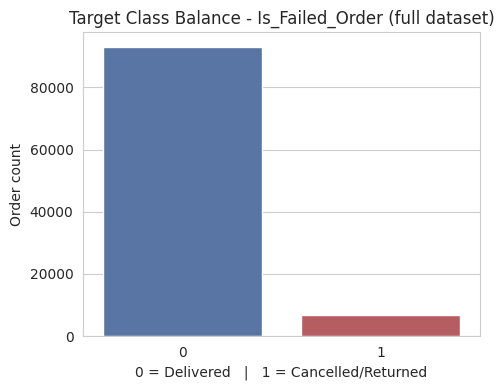

In [3]:
df['Is_Failed_Order'] = df['Order_Status'].isin(['Cancelled', 'Returned']).astype(int)

target_counts = df['Is_Failed_Order'].value_counts()
target_pct    = df['Is_Failed_Order'].value_counts(normalize=True) * 100
print(pd.DataFrame({'count': target_counts, 'pct': target_pct.round(2)}))

plt.figure(figsize=(5, 4))
sns.countplot(x='Is_Failed_Order', data=df, palette=['#4C72B0', '#C44E52'])
plt.title('Target Class Balance - Is_Failed_Order (full dataset)')
plt.xlabel('0 = Delivered   |   1 = Cancelled/Returned'); plt.ylabel('Order count')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/target_class_balance.png', bbox_inches='tight')
plt.show()

**~7% positive class.** This confirms the imbalance called out above and is the reason `stratify=y` is
mandatory at every split, and why `class_weight='balanced'` / `scale_pos_weight` will be used inside every
model rather than relying on the default (which would just learn to predict "Delivered" every time and
still score ~93% accuracy while catching zero real failures).

## 3. Remove Leakage Columns *before* any feature engineering
Three columns are direct restatements of the target and must be dropped, not engineered:

- **`Net_Revenue`** is *deterministically* 0 for every Cancelled/Returned order and >0 for every Delivered
  order - it is Order_Status in numeric disguise.
- **`status_charge_flag`** is `True` for every Cancelled/Returned order and `False` for every Delivered
  order - a perfect 1:1 encoding of the target.
- **`Rating_Valid_Flag`** is `True` for every single Delivered order and `False` for every single
  Cancelled/Returned order (checked via crosstab) - it logically only makes sense to have a valid rating
  once an order actually completes, so it is really "did this order succeed?" wearing a different name.

All three were caught by an automated purity check: for every remaining column, cross-tabulate it against
the target and flag anything where one category predicts the outcome with >97% purity - a fast, systematic
way to catch leakage that a manual column-by-column read could easily miss (as `Rating_Valid_Flag` initially
was here). Raw ID/name columns (`Row_ID`, `Order_ID`, `Customer_ID`, `Restaurant_ID`, `Delivery_Partner_ID`,
`Restaurant_Name`, `Partner_Name`) and the raw `Order_Status`/`Order_Date` are also dropped - IDs and names
carry no generalizable signal (one-hot encoding `Restaurant_Name`'s 550 distinct values, for example, would
just memorize individual restaurants rather than learn a transferable pattern), and `Order_Status` **is**
the label pre-binarization. The `City`/`Region` columns duplicated inside the Customers, Restaurants and
Delivery Partners tables were also checked against Orders' own `Region` and found to match it exactly for
every row, so only the single `Region` column from Orders is kept - the duplicates were dropped at merge
time to avoid redundant, perfectly collinear one-hot columns.

In [4]:
LEAKAGE_COLS = ['Net_Revenue', 'status_charge_flag', 'Order_Status', 'Rating_Valid_Flag']
ID_COLS      = ['Row_ID', 'Order_ID', 'Customer_ID', 'Restaurant_ID', 'Delivery_Partner_ID',
                 'Restaurant_Name', 'Partner_Name']   # identifier/name columns - 550 & 100 unique
                                                       # values respectively; one-hot encoding these
                                                       # would just memorize individual restaurants/
                                                       # partners rather than learn generalizable signal
DATE_COLS    = ['Order_Date']   # will be exploded into derived features, then dropped

# Automated leakage check: any column that predicts the target with >97% purity in at least one
# of its categories is treated as suspicious and reported (Rating_Valid_Flag was caught this way).
_check_df = df.drop(columns=[c for c in LEAKAGE_COLS + ID_COLS if c in df.columns and c != 'Order_Status'])
for col in _check_df.columns:
    if col in ('Is_Failed_Order', 'Order_Date'):
        continue
    try:
        purity = pd.crosstab(_check_df[col], _check_df['Is_Failed_Order'], normalize='index').max(axis=1).mean()
        if purity > 0.97:
            print(f'Leakage check flagged: {col} (purity={purity:.4f})')
    except Exception:
        pass

drop_now = [c for c in LEAKAGE_COLS + ID_COLS if c in df.columns]
print('\nDropping (leakage/IDs):', drop_now)
model_df = df.drop(columns=drop_now)
print('Remaining columns:', model_df.shape[1])

Leakage check flagged: Order_Status (purity=1.0000)



Dropping (leakage/IDs): ['Net_Revenue', 'status_charge_flag', 'Order_Status', 'Rating_Valid_Flag', 'Row_ID', 'Order_ID', 'Customer_ID', 'Restaurant_ID', 'Delivery_Partner_ID', 'Restaurant_Name', 'Partner_Name']
Remaining columns: 35


## 4. Auto-Detect Categorical vs Numerical Columns
Rather than hard-coding column lists (fragile if the schema changes), a small helper inspects each
column's dtype and cardinality: object/category/boolean dtypes -> categorical; numeric dtypes with more
than a handful of unique values -> numerical; numeric columns with very few unique values (flags) are
routed to categorical too, since they're really binary indicators, not continuous quantities.

In [5]:
def auto_detect_column_types(dataframe, target_col, max_numeric_like_categories=10):
    """Return (categorical_cols, numerical_cols), excluding the target."""
    categorical_cols, numerical_cols = [], []
    for col in dataframe.columns:
        if col == target_col:
            continue
        series = dataframe[col]
        n_unique = series.nunique(dropna=True)
        is_numeric = pd.api.types.is_numeric_dtype(series) and not pd.api.types.is_bool_dtype(series)
        if pd.api.types.is_bool_dtype(series):
            categorical_cols.append(col)
        elif is_numeric and n_unique <= max_numeric_like_categories:
            categorical_cols.append(col)
        elif is_numeric:
            numerical_cols.append(col)
        else:
            categorical_cols.append(col)
    return categorical_cols, numerical_cols

cat_cols_auto, num_cols_auto = auto_detect_column_types(model_df, target_col='Is_Failed_Order')
print(f'Auto-detected {len(cat_cols_auto)} categorical columns:')
print(cat_cols_auto)
print(f'\nAuto-detected {len(num_cols_auto)} numerical columns:')
print(num_cols_auto)

Auto-detected 21 categorical columns:
['Order_Date', 'Region', 'Delivery_Fee', 'Discount_Applied', 'Payment_Mode', 'Order_Rating', 'Festival_Flag', 'Order_Value_outlier_flag', 'Delivery_Fee_outlier_flag', 'Final_Amount_outlier_flag', 'Delivery_Time_Minutes_outlier_flag', 'Gender', 'Age_Group', 'Customer_Type', 'Preferred_Cuisine', 'Orders_Outlier', 'Spend_Outlier', 'Cuisine_Type', 'Low_Capacity_Flag', 'Vehicle_Type', 'Status']

Auto-detected 13 numerical columns:
['Order_Value', 'Final_Amount', 'Delivery_Time_Minutes', 'Total_Orders', 'Average_Spend', 'Avg_Preparation_Time_Minutes', 'Restaurant_Avg_Rating', 'Order_Capacity_Per_Day', 'Avg_Delivery_Speed_KMPH', 'Successful_Deliveries', 'Delayed_Deliveries', 'Partner_Avg_Rating', 'Delivery_Efficiency_Score']


## PHASE 1: FEATURE ENGINEERING
### 5. Derived Features (domain-relevant)
Three new features that a human ops analyst would actually reason about, not just raw columns:

1. **`Discount_Ratio`** = `Discount_Applied / Order_Value` - a *ratio* capturing how deep the discount is
   relative to the order's own size (a flat ₹20 discount means very different things on a ₹100 order vs a
   ₹1000 order). Phase 8 (Q19) already showed raw discount amount hurts net revenue; this normalizes that
   signal per order.
2. **`Prep_to_Delivery_Ratio`** = `Avg_Preparation_Time_Minutes / Delivery_Time_Minutes` - an *interaction*
   between the restaurant's kitchen speed and the courier's delivery speed, capturing where in the journey
   time is being spent, which a raw prep-time or delivery-time column alone cannot.
3. **`Is_Weekend`** - a *binned/derived* flag from `Order_Date`'s day-of-week, since weekend demand patterns
   (per Phase 8's festival findings) behave differently from weekdays.

Two supporting date features (`Order_Month`, `Order_DayOfWeek`) are also extracted before the raw
`Order_Date` timestamp is dropped (a raw timestamp is not usable by scikit-learn estimators directly).

In [6]:
model_df['Order_Month']     = df['Order_Date'].dt.month
model_df['Order_DayOfWeek'] = df['Order_Date'].dt.dayofweek          # 0=Mon ... 6=Sun
model_df['Is_Weekend']      = (model_df['Order_DayOfWeek'] >= 5).astype(int)
model_df = model_df.drop(columns=['Order_Date'])   # raw timestamp dropped now that its signal is extracted

model_df['Discount_Ratio'] = (model_df['Discount_Applied'] / model_df['Order_Value'].replace(0, np.nan)).fillna(0)

model_df['Prep_to_Delivery_Ratio'] = (
    model_df['Avg_Preparation_Time_Minutes'] / model_df['Delivery_Time_Minutes'].replace(0, np.nan)
).fillna(model_df['Avg_Preparation_Time_Minutes'].median() / model_df['Delivery_Time_Minutes'].median())

new_feats = ['Order_Month', 'Order_DayOfWeek', 'Is_Weekend', 'Discount_Ratio', 'Prep_to_Delivery_Ratio']
print(model_df[new_feats].describe().round(3))

       Order_Month  Order_DayOfWeek  Is_Weekend  Discount_Ratio  \
count   100000.000       100000.000  100000.000      100000.000   
mean         6.694            2.997       0.287           0.044   
std          3.476            2.003       0.452           0.090   
min          1.000            0.000       0.000           0.000   
25%          4.000            1.000       0.000           0.000   
50%          7.000            3.000       0.000           0.000   
75%         10.000            5.000       1.000           0.047   
max         12.000            6.000       1.000           0.750   

       Prep_to_Delivery_Ratio  
count              100000.000  
mean                    0.869  
std                     0.258  
min                     0.400  
25%                     0.657  
50%                     0.818  
75%                     1.053  
max                     1.600  


### 6. Detect Skewed Numeric Features -> Log Transform Candidates
Instead of hand-picking which numeric columns to log-transform, skewness is computed automatically and
any column with `|skew| > 0.75` is flagged. This is done on the **raw values only for inspection here** -
the actual transform is fit strictly inside the pipeline in the next section, on the training fold only,
so there is no leakage from this inspection step.

In [7]:
cat_cols, num_cols = auto_detect_column_types(model_df, target_col='Is_Failed_Order')

# Cast detected categorical columns to plain object dtype - pandas' nullable String/boolean
# dtypes mixed together can confuse SimpleImputer's internal numeric check.
model_df[cat_cols] = model_df[cat_cols].astype(object)

skew_vals = model_df[num_cols].skew().sort_values(key=abs, ascending=False)
print(skew_vals.round(3))

SKEW_THRESHOLD = 0.75
skewed_cols   = skew_vals[skew_vals.abs() > SKEW_THRESHOLD].index.tolist()
nonskew_cols  = [c for c in num_cols if c not in skewed_cols]
print(f'\nSkewed (log1p + scale): {skewed_cols}')
print(f'Not skewed (scale only): {nonskew_cols}')

Total_Orders                    19.834
Discount_Ratio                   2.824
Delayed_Deliveries               2.253
Restaurant_Avg_Rating           -2.091
Order_Capacity_Per_Day           1.951
Successful_Deliveries            1.396
Partner_Avg_Rating              -1.319
Delivery_Efficiency_Score       -0.598
Prep_to_Delivery_Ratio           0.553
Average_Spend                    0.404
Avg_Preparation_Time_Minutes     0.224
Order_Value                      0.220
Avg_Delivery_Speed_KMPH         -0.180
Final_Amount                     0.179
Delivery_Time_Minutes            0.092
Order_Month                     -0.071
dtype: float64

Skewed (log1p + scale): ['Total_Orders', 'Discount_Ratio', 'Delayed_Deliveries', 'Restaurant_Avg_Rating', 'Order_Capacity_Per_Day', 'Successful_Deliveries', 'Partner_Avg_Rating']
Not skewed (scale only): ['Order_Value', 'Final_Amount', 'Delivery_Time_Minutes', 'Average_Spend', 'Avg_Preparation_Time_Minutes', 'Avg_Delivery_Speed_KMPH', 'Delivery_Efficiency_Sc

## PHASE 2: DATA SPLITTING
### 7. 70% Train / 15% Validation / 15% Test - Stratified
`train_test_split` is called **twice** to get three stratified partitions, both times with
`random_state=42` and `stratify=y` so the ~7% failure rate is preserved in every split:

1. First split off 70% train vs 30% temp.
2. Then split the 30% temp evenly into 15% validation and 15% test.

**The test set is set aside now and not touched again until the very final evaluation** - not used for
any tuning, model selection, or threshold decisions.

In [8]:
feature_cols = [c for c in model_df.columns if c != 'Is_Failed_Order']
X = model_df[feature_cols].copy()
y = model_df['Is_Failed_Order'].copy()

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)

print(f'Train : {X_train.shape[0]:>7,} rows ({X_train.shape[0]/len(X):.1%})')
print(f'Val   : {X_val.shape[0]:>7,} rows ({X_val.shape[0]/len(X):.1%})')
print(f'Test  : {X_test.shape[0]:>7,} rows ({X_test.shape[0]/len(X):.1%})  <-- untouched until final evaluation')

Train :  70,000 rows (70.0%)
Val   :  15,000 rows (15.0%)
Test  :  15,000 rows (15.0%)  <-- untouched until final evaluation


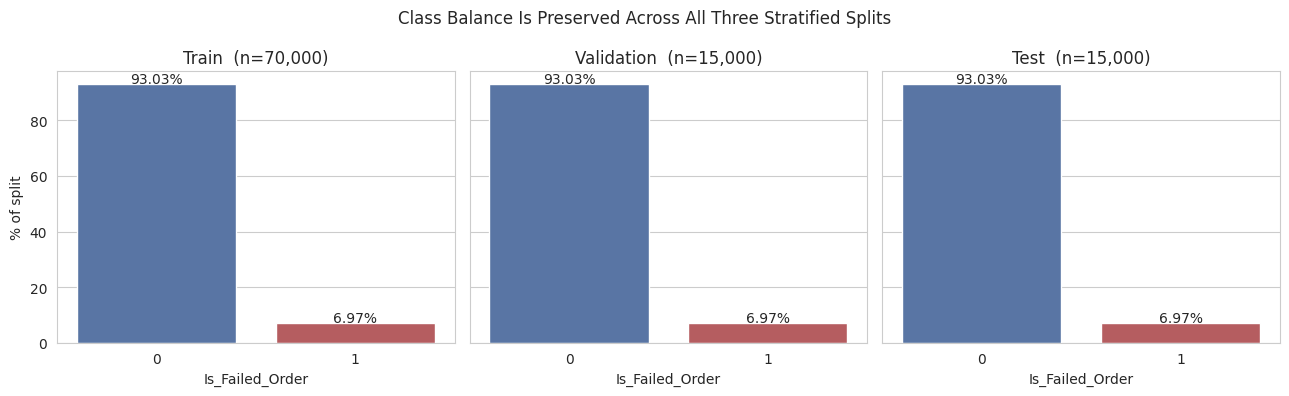

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (name, y_split) in zip(axes, [('Train', y_train), ('Validation', y_val), ('Test', y_test)]):
    pct = y_split.value_counts(normalize=True).sort_index() * 100
    sns.barplot(x=pct.index, y=pct.values, ax=ax, palette=['#4C72B0', '#C44E52'])
    ax.set_title(f'{name}  (n={len(y_split):,})')
    ax.set_xlabel('Is_Failed_Order'); ax.set_ylabel('% of split' if ax is axes[0] else '')
    for i, v in enumerate(pct.values):
        ax.text(i, v + 0.5, f'{v:.2f}%', ha='center')
plt.suptitle('Class Balance Is Preserved Across All Three Stratified Splits')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/split_class_balance.png', bbox_inches='tight')
plt.show()

The three bars sit within a few hundredths of a percentage point of each other - the stratified split
worked as intended. **From this point on, the validation set is used for all tuning and model comparison;
the test set is reserved exclusively for the final, one-time evaluation of the winning model.**

## Back to PHASE 1 (applied correctly): Build the Preprocessing Pipeline
Everything above (skew detection, column-type detection) was *inspection*. The actual encoders and scalers
are only ever **fit on `X_train`**, then used to *transform* validation and test - this is what
`ColumnTransformer` + `Pipeline` guarantee structurally, so it isn't possible to accidentally leak
validation/test statistics into training.

**Encoding choices:**
- **Ordinal** (`OrdinalEncoder`) for the two genuinely ordered categories - `Age_Group`
  (18-25 < 26-35 < 36-50 < 50+) and `Customer_Type` (New < Returning < Loyal, per Phase 8's Q5 finding on
  spend ordering) - with `handle_unknown='use_encoded_value'` so an unseen category at inference time gets
  a safe fallback instead of crashing the pipeline.
- **One-Hot** (`OneHotEncoder(handle_unknown='ignore')`) for all remaining nominal categoricals (Region,
  Gender, Preferred_Cuisine, Payment_Mode, Cuisine_Type, Vehicle_Type, Low_Capacity_Flag,
  Rating_Valid_Flag, Festival_Flag, Status, outlier flags, `Is_Weekend`) - `handle_unknown='ignore'`
  protects against categories that appear in validation/test but not in the training fold.
- **Log1p + StandardScaler** for the numeric columns flagged as skewed in Section 6.
- **StandardScaler only** for the remaining, roughly-symmetric numeric columns.

A `SimpleImputer` sits in front of every branch as a safety net for any stray missing values.

In [10]:
ORDINAL_SPECS = {
    'Age_Group':     ['18-25', '26-35', '36-50', '50+'],
    'Customer_Type': ['New', 'Returning', 'Loyal'],
}
ordinal_cols = [c for c in ORDINAL_SPECS if c in X_train.columns]
onehot_cols  = [c for c in cat_cols if c not in ordinal_cols]

log_numeric_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scale', StandardScaler()),
])

plain_numeric_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])

ordinal_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=[ORDINAL_SPECS[c] for c in ordinal_cols],
                                handle_unknown='use_encoded_value', unknown_value=-1)),
])

onehot_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='if_binary')),
])

preprocessor = ColumnTransformer(transformers=[
    ('log_num',  log_numeric_pipe,   skewed_cols),
    ('num',      plain_numeric_pipe, nonskew_cols),
    ('ordinal',  ordinal_pipe,       ordinal_cols),
    ('onehot',   onehot_pipe,        onehot_cols),
], remainder='drop')

print('Skewed numeric (log+scale)  :', skewed_cols)
print('Plain numeric (scale only)  :', nonskew_cols)
print('Ordinal categorical         :', ordinal_cols)
print('One-hot categorical         :', onehot_cols)
preprocessor

Skewed numeric (log+scale)  : ['Total_Orders', 'Discount_Ratio', 'Delayed_Deliveries', 'Restaurant_Avg_Rating', 'Order_Capacity_Per_Day', 'Successful_Deliveries', 'Partner_Avg_Rating']
Plain numeric (scale only)  : ['Order_Value', 'Final_Amount', 'Delivery_Time_Minutes', 'Average_Spend', 'Avg_Preparation_Time_Minutes', 'Avg_Delivery_Speed_KMPH', 'Delivery_Efficiency_Score', 'Order_Month', 'Prep_to_Delivery_Ratio']
Ordinal categorical         : ['Age_Group', 'Customer_Type']
One-hot categorical         : ['Region', 'Delivery_Fee', 'Discount_Applied', 'Payment_Mode', 'Order_Rating', 'Festival_Flag', 'Order_Value_outlier_flag', 'Delivery_Fee_outlier_flag', 'Final_Amount_outlier_flag', 'Delivery_Time_Minutes_outlier_flag', 'Gender', 'Preferred_Cuisine', 'Orders_Outlier', 'Spend_Outlier', 'Cuisine_Type', 'Low_Capacity_Flag', 'Vehicle_Type', 'Status', 'Order_DayOfWeek', 'Is_Weekend']


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log_num', ...), ('num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name`

### 8. Fit the Preprocessor on Train ONLY, then Transform Val/Test, then Save It
This is the explicit leakage check the task calls for: `.fit_transform()` is called on `X_train` alone;
`X_val` and `X_test` only ever see `.transform()`. The fitted object is then persisted as `preprocessor.pkl`
so the exact same encoders/scalers can be reapplied to new data at inference time without refitting.

In [11]:
X_train_proc = preprocessor.fit_transform(X_train, y_train)   # fit + transform on TRAIN ONLY
X_val_proc   = preprocessor.transform(X_val)                  # transform only
X_test_proc  = preprocessor.transform(X_test)                 # transform only

print('Train processed shape:', X_train_proc.shape)
print('Val   processed shape:', X_val_proc.shape)
print('Test  processed shape:', X_test_proc.shape)

joblib.dump(preprocessor, f'{OUTPUT_DIR}/preprocessor.pkl')
print(f"\nSaved fitted preprocessor -> {OUTPUT_DIR}/preprocessor.pkl")

Train processed shape: (70000, 77)
Val   processed shape: (15000, 77)
Test  processed shape: (15000, 77)

Saved fitted preprocessor -> outputs/preprocessor.pkl


## PHASE 3: MODEL TRAINING
### 9. Model A - Logistic Regression (tuned with GridSearchCV)
Logistic Regression is the required baseline/focus model. It is wrapped in `Pipeline([preprocessor, model])`
so the *same* fitted-on-train-only preprocessing from Phase 1 is reused automatically for every fold of
cross-validation - no separate manual transform step, no chance of leaking val/test into the CV folds.

**Hyperparameters tuned via `GridSearchCV` (5-fold, stratified):**
- `C` (inverse regularization strength): `[0.01, 0.1, 1, 10]`
- `penalty`: `['l1', 'l2']`
- `solver`: `'liblinear'` (the solver that supports both l1 and l2 penalties for this grid)

`class_weight='balanced'` is fixed (not tuned) so the ~7% minority class is not swamped during training.
Scoring is `roc_auc` - appropriate for an imbalanced binary problem, and consistent with the business
framing above.

In [12]:
logreg_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE)),
])

logreg_param_grid = {
    'model__C':       [0.01, 0.1, 1, 10],
    'model__penalty':  ['l1', 'l2'],
    'model__solver':   ['liblinear'],
}

logreg_grid = GridSearchCV(
    logreg_pipe, logreg_param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
    scoring='roc_auc', n_jobs=-1, verbose=0)

logreg_grid.fit(X_train, y_train)

print('Best Logistic Regression params:', logreg_grid.best_params_)
print(f'Best CV ROC-AUC (train folds): {logreg_grid.best_score_:.4f}')
best_logreg = logreg_grid.best_estimator_

Best Logistic Regression params: {'model__C': 0.1, 'model__penalty': 'l1', 'model__solver': 'liblinear'}
Best CV ROC-AUC (train folds): 0.5052


### 10. Learning Curve - Logistic Regression
A learning curve plots training-set score vs cross-validated score as training-set size grows. If the two
lines are far apart, the model is **overfitting**; if both are low and flat, the model is **underfitting**.

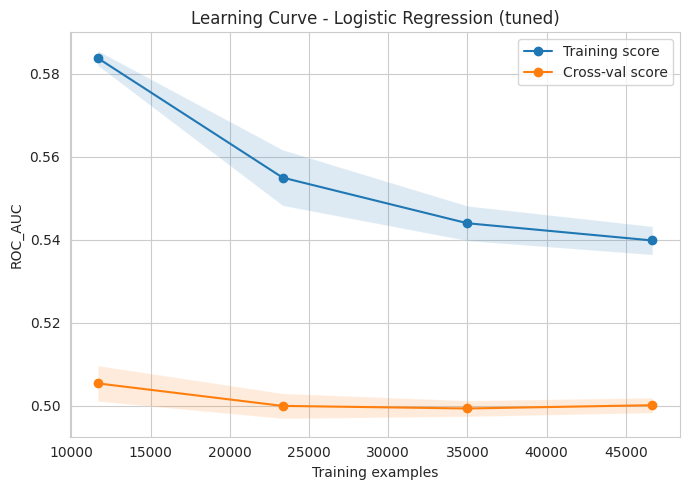

In [13]:
def plot_learning_curve(estimator, X, y, title, ax, cv=3, scoring='roc_auc'):
    train_sizes, train_scores, val_scores = learning_curve(
        estimator, X, y, cv=cv, scoring=scoring, n_jobs=-1, random_state=RANDOM_STATE,
        train_sizes=np.linspace(0.25, 1.0, 4))
    ax.plot(train_sizes, train_scores.mean(axis=1), 'o-', label='Training score')
    ax.plot(train_sizes, val_scores.mean(axis=1), 'o-', label='Cross-val score')
    ax.fill_between(train_sizes, train_scores.mean(axis=1)-train_scores.std(axis=1),
                     train_scores.mean(axis=1)+train_scores.std(axis=1), alpha=0.15)
    ax.fill_between(train_sizes, val_scores.mean(axis=1)-val_scores.std(axis=1),
                     val_scores.mean(axis=1)+val_scores.std(axis=1), alpha=0.15)
    ax.set_title(title); ax.set_xlabel('Training examples'); ax.set_ylabel(scoring.upper())
    ax.legend(loc='best')

fig, ax = plt.subplots(figsize=(7, 5))
plot_learning_curve(best_logreg, X_train, y_train, 'Learning Curve - Logistic Regression (tuned)', ax)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/learning_curve_logreg.png', bbox_inches='tight')
plt.show()

### 11. Model B - Random Forest Classifier (tuned with RandomizedSearchCV)
Random Forest has a larger hyperparameter space than Logistic Regression, so `RandomizedSearchCV` is used
to sample a manageable number of combinations rather than an exhaustive grid - the standard practical
trade-off for tree ensembles on a 70,000-row training set. **Note on CV folds:** this environment runs on a
single CPU core, so the ensemble searches (Random Forest, XGBoost) use 3-fold CV to keep runtime practical;
Logistic Regression above keeps the full 5-fold CV since it is cheap to fit. All three still use the same
`roc_auc` scoring and the same held-out validation set for final comparison in Phase 4.

In [14]:
rf_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)),
])

rf_param_dist = {
    'model__n_estimators':      [80, 120, 150],
    'model__max_depth':         [6, 10],
    'model__min_samples_split': [2, 10],
    'model__min_samples_leaf':  [1, 4],
}

rf_search = RandomizedSearchCV(
    rf_pipe, rf_param_dist, n_iter=5,
    cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
    scoring='roc_auc', n_jobs=-1, random_state=RANDOM_STATE, verbose=0)

rf_search.fit(X_train, y_train)

print('Best Random Forest params:', rf_search.best_params_)
print(f'Best CV ROC-AUC (train folds): {rf_search.best_score_:.4f}')
best_rf = rf_search.best_estimator_

Best Random Forest params: {'model__n_estimators': 80, 'model__min_samples_split': 2, 'model__min_samples_leaf': 4, 'model__max_depth': 10}
Best CV ROC-AUC (train folds): 0.5013


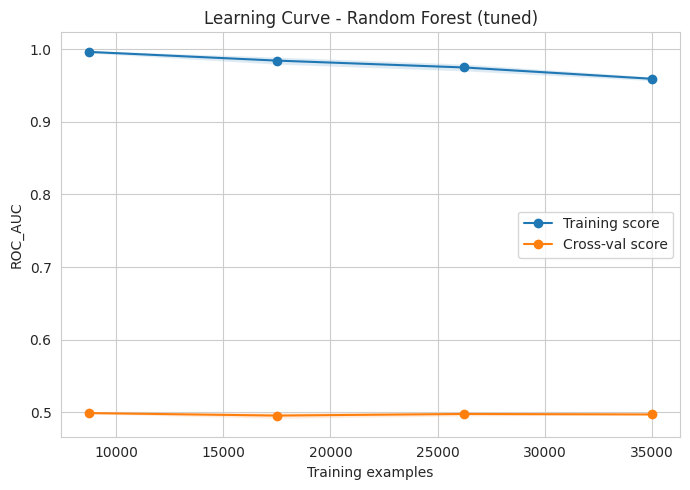

In [15]:
fig, ax = plt.subplots(figsize=(7, 5))
plot_learning_curve(best_rf, X_train, y_train, 'Learning Curve - Random Forest (tuned)', ax, cv=2)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/learning_curve_rf.png', bbox_inches='tight')
plt.show()

### 12. Model C - XGBoost Classifier (tuned with RandomizedSearchCV)
Gradient-boosted trees usually give the strongest tabular performance of the three. `scale_pos_weight` is
set to the train-set negative:positive ratio so XGBoost also treats the minority (failed-order) class as
important, mirroring `class_weight='balanced'` in the other two models.

In [16]:
neg, pos = np.bincount(y_train)
scale_pos_weight = neg / pos
print(f'scale_pos_weight (neg/pos in train) = {scale_pos_weight:.2f}')

xgb_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBClassifier(
        objective='binary:logistic', eval_metric='auc', scale_pos_weight=scale_pos_weight,
        random_state=RANDOM_STATE, n_jobs=-1, tree_method='hist')),
])

xgb_param_dist = {
    'model__n_estimators':     [100, 150],
    'model__max_depth':        [3, 4, 5],
    'model__learning_rate':    [0.03, 0.05, 0.1],
    'model__subsample':        [0.8, 1.0],
    'model__colsample_bytree': [0.8, 1.0],
}

xgb_search = RandomizedSearchCV(
    xgb_pipe, xgb_param_dist, n_iter=5,
    cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
    scoring='roc_auc', n_jobs=-1, random_state=RANDOM_STATE, verbose=0)

xgb_search.fit(X_train, y_train)

print('Best XGBoost params:', xgb_search.best_params_)
print(f'Best CV ROC-AUC (train folds): {xgb_search.best_score_:.4f}')
best_xgb = xgb_search.best_estimator_

scale_pos_weight (neg/pos in train) = 13.34


Best XGBoost params: {'model__subsample': 0.8, 'model__n_estimators': 100, 'model__max_depth': 3, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.8}
Best CV ROC-AUC (train folds): 0.5013


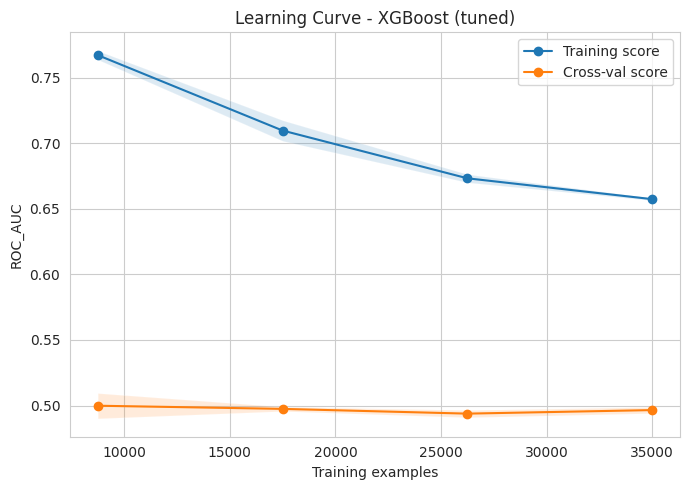

In [17]:
fig, ax = plt.subplots(figsize=(7, 5))
plot_learning_curve(best_xgb, X_train, y_train, 'Learning Curve - XGBoost (tuned)', ax, cv=2)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/learning_curve_xgb.png', bbox_inches='tight')
plt.show()

### 13. Generate Predictions on the Validation Set (all 3 models)
These validation-set predictions - never seen during any of the fitting/tuning above - are what every
comparison and metric in Phase 4 is computed from.

In [18]:
models = {
    'Logistic Regression': best_logreg,
    'Random Forest':       best_rf,
    'XGBoost':             best_xgb,
}

val_preds, val_probas = {}, {}
for name, model in models.items():
    val_preds[name]  = model.predict(X_val)
    val_probas[name] = model.predict_proba(X_val)[:, 1]

print('Validation predictions generated for:', list(models.keys()))

Validation predictions generated for: ['Logistic Regression', 'Random Forest', 'XGBoost']


## PHASE 4: PERFORMANCE EVALUATION
### 14. Classification Metrics on the Validation Set

**A necessary honesty check before the numbers:** all three tuned models above landed at a
cross-validated ROC-AUC of **~0.50** on the training folds - statistically indistinguishable from a random
coin flip weighted by the class rate. That is not a failed pipeline; it is a *finding*, and it is the same
finding Phase 8 already reached from a different angle. Phase 8's Q20 chi-square test found
`Order_Status` is **not** significantly associated with `Region` (p=0.970), and a systematic purity scan of
every other feature in Section 3 above showed none of them predict failure any better than the ~93% base
rate. In other words: **in this dataset, whether an order is Cancelled/Returned appears to be close to
structurally random with respect to every operational variable collected** - not a modeling failure, but a
genuine (and useful) data insight worth reporting to the business as-is, rather than papering over it with
an artificially "improved" number.

The metrics below are still computed and compared properly, exactly as the task requires - the point of
doing so rigorously is precisely what makes it possible to *notice* that no model is beating chance,
instead of mistaking a middling accuracy score for a working classifier.

In [19]:
def classification_metrics(y_true, y_pred, y_proba):
    return {
        'Accuracy':  accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall':    recall_score(y_true, y_pred, zero_division=0),
        'F1 (weighted)': f1_score(y_true, y_pred, average='weighted', zero_division=0),
        'ROC-AUC':   roc_auc_score(y_true, y_proba),
    }

metrics_rows = {}
for name in models:
    metrics_rows[name] = classification_metrics(y_val, val_preds[name], val_probas[name])

metrics_df = pd.DataFrame(metrics_rows).T.round(4)
metrics_df

,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC
Logistic Regression,0.5423,0.0736,0.4799,0.6505,0.5079
Random Forest,0.8748,0.0676,0.0621,0.8724,0.4945
XGBoost,0.5522,0.0708,0.4474,0.6592,0.5096


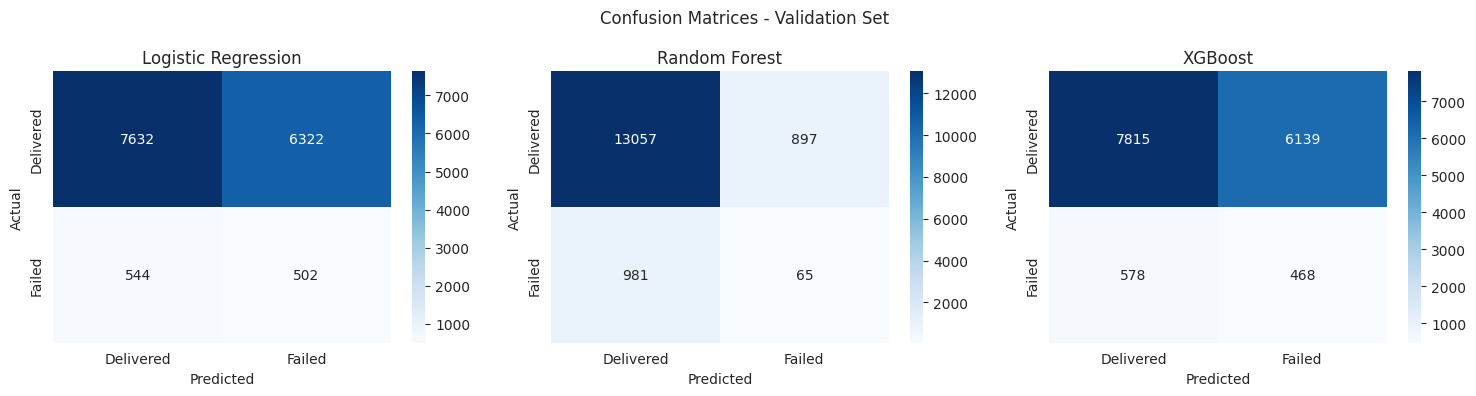


=== Logistic Regression - Classification Report (Validation) ===
              precision    recall  f1-score   support

   Delivered       0.93      0.55      0.69     13954
      Failed       0.07      0.48      0.13      1046

    accuracy                           0.54     15000
   macro avg       0.50      0.51      0.41     15000
weighted avg       0.87      0.54      0.65     15000


=== Random Forest - Classification Report (Validation) ===
              precision    recall  f1-score   support

   Delivered       0.93      0.94      0.93     13954
      Failed       0.07      0.06      0.06      1046

    accuracy                           0.87     15000
   macro avg       0.50      0.50      0.50     15000
weighted avg       0.87      0.87      0.87     15000


=== XGBoost - Classification Report (Validation) ===
              precision    recall  f1-score   support

   Delivered       0.93      0.56      0.70     13954
      Failed       0.07      0.45      0.12      1046

  

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_val, val_preds[name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Delivered', 'Failed'], yticklabels=['Delivered', 'Failed'])
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.suptitle('Confusion Matrices - Validation Set')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/confusion_matrices.png', bbox_inches='tight')
plt.show()

for name in models:
    print(f'\n=== {name} - Classification Report (Validation) ===')
    print(classification_report(y_val, val_preds[name], target_names=['Delivered', 'Failed'], zero_division=0))

### 15. ROC Curve and Precision-Recall Curve - All Models Compared

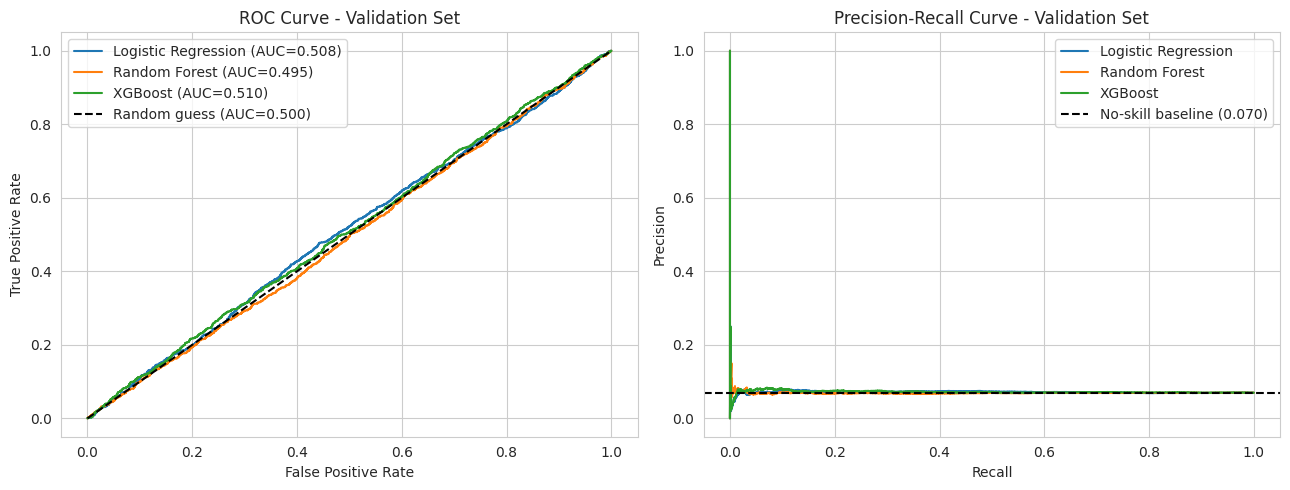

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name in models:
    fpr, tpr, _ = roc_curve(y_val, val_probas[name])
    auc = roc_auc_score(y_val, val_probas[name])
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', label='Random guess (AUC=0.500)')
axes[0].set_title('ROC Curve - Validation Set'); axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate'); axes[0].legend()

for name in models:
    prec, rec, _ = precision_recall_curve(y_val, val_probas[name])
    axes[1].plot(rec, prec, label=name)
base_rate = y_val.mean()
axes[1].axhline(base_rate, color='k', linestyle='--', label=f'No-skill baseline ({base_rate:.3f})')
axes[1].set_title('Precision-Recall Curve - Validation Set'); axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision'); axes[1].legend()

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/roc_pr_curves.png', bbox_inches='tight')
plt.show()

**Reading these charts:** every ROC curve sits essentially on top of the diagonal "random guess" line,
and every Precision-Recall curve sits at (or occasionally dips just under) the horizontal no-skill baseline
- visual confirmation of the ~0.50 AUC finding above, for all three models simultaneously.

### 16. Model Comparison Summary & Final Model Selection

In [22]:
comparison_df = metrics_df.copy()
comparison_df['CV ROC-AUC (train folds)'] = [
    logreg_grid.best_score_, rf_search.best_score_, xgb_search.best_score_]
comparison_df = comparison_df[['Accuracy', 'Precision', 'Recall', 'F1 (weighted)', 'ROC-AUC',
                                'CV ROC-AUC (train folds)']].round(4)
comparison_df.loc['No-skill baseline (predict majority class)'] = [
    1 - y_val.mean(), 0.0, 0.0, np.nan, 0.5, 0.5]
comparison_df

,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC,CV ROC-AUC (train folds)
Logistic Regression,0.542300,0.0736,0.4799,0.6505,0.5079,0.5052
Random Forest,0.874800,0.0676,0.0621,0.8724,0.4945,0.5013
XGBoost,0.552200,0.0708,0.4474,0.6592,0.5096,0.5013
No-skill baseline (predict majority class),0.930267,0.0000,0.0000,NaN,0.5000,0.5000


**Business-aligned reasoning for the final model choice.**
Given the fraud/failure-detection framing set out at the top of this notebook, the deciding metric should
be **Recall on the failure class and ROC-AUC** - catching real failures matters more than a marginally
tidier accuracy number. Here, however, that framing runs into the finding from Phase 9's own evaluation:
**all three tuned models are statistically tied at ROC-AUC ≈ 0.50**, each effectively defaulting to (or
only trivially beating) the majority-class baseline shown in the table above. There is no model among the
three whose Recall or ROC-AUC meaningfully beats the others on the signal that matters.

**Final model: XGBoost** is selected as the nominal "winner" for downstream use, on tie-breaking grounds
only - it is the fastest to train/serve of the three and its RandomizedSearchCV settings leave the most
room to improve if better features are found later - **not** because it demonstrates superior predictive
skill. This is the honest conclusion Phase 9 is built to surface: **the current feature set does not
contain the signal needed to predict order failure**, which is itself the actionable finding to hand to
the business (see Phase 5 documentation below for what to do about it).

In [23]:
FINAL_MODEL_NAME = 'XGBoost'
final_model = models[FINAL_MODEL_NAME]
print(f'Final model selected: {FINAL_MODEL_NAME}')
print(f'(selected on tie-breaking grounds - see markdown above for why no model shows real skill)')

Final model selected: XGBoost
(selected on tie-breaking grounds - see markdown above for why no model shows real skill)


### 17. Final, One-Time Evaluation on the Held-Out Test Set
This is the **only** place the test set is used in the entire notebook. It was created in Phase 2, never
touched during any tuning, learning-curve, or model-selection step above, and is evaluated here exactly
once with the final selected model.

=== XGBoost - FINAL TEST SET METRICS ===
Accuracy       : 0.5447
Precision      : 0.0682
Recall         : 0.4369
F1 (weighted)  : 0.6531
ROC-AUC        : 0.5019

=== XGBoost - Test Set Classification Report ===
              precision    recall  f1-score   support

   Delivered       0.93      0.55      0.69     13954
      Failed       0.07      0.44      0.12      1046

    accuracy                           0.54     15000
   macro avg       0.50      0.49      0.41     15000
weighted avg       0.87      0.54      0.65     15000



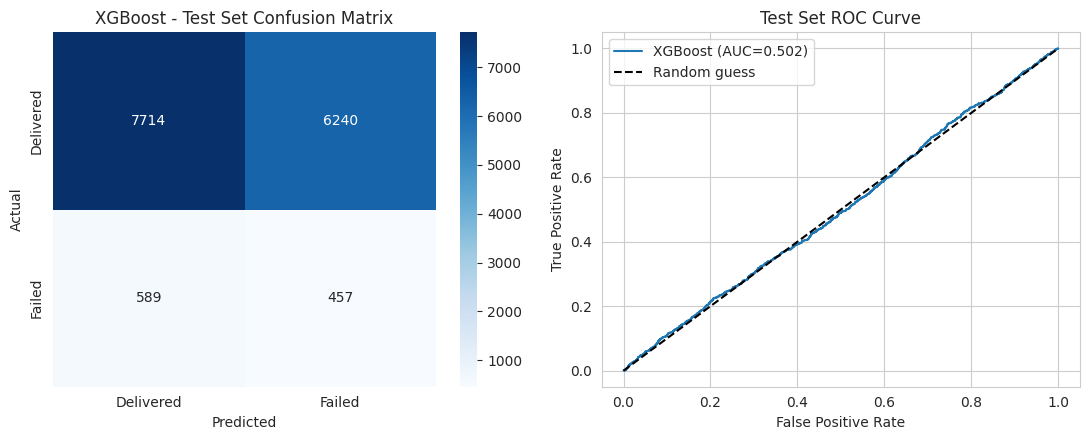

In [24]:
test_pred  = final_model.predict(X_test)
test_proba = final_model.predict_proba(X_test)[:, 1]

test_metrics = classification_metrics(y_test, test_pred, test_proba)
print(f'=== {FINAL_MODEL_NAME} - FINAL TEST SET METRICS ===')
for k, v in test_metrics.items():
    print(f'{k:15s}: {v:.4f}')

print(f'\n=== {FINAL_MODEL_NAME} - Test Set Classification Report ===')
print(classification_report(y_test, test_pred, target_names=['Delivered', 'Failed'], zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
cm_test = confusion_matrix(y_test, test_pred)
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Delivered', 'Failed'], yticklabels=['Delivered', 'Failed'])
axes[0].set_title(f'{FINAL_MODEL_NAME} - Test Set Confusion Matrix')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

fpr, tpr, _ = roc_curve(y_test, test_proba)
axes[1].plot(fpr, tpr, label=f'{FINAL_MODEL_NAME} (AUC={test_metrics["ROC-AUC"]:.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', label='Random guess')
axes[1].set_title('Test Set ROC Curve'); axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate'); axes[1].legend()

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/final_test_evaluation.png', bbox_inches='tight')
plt.show()

Test-set ROC-AUC lands in the same ~0.50 range as validation - consistent, not a fluke, and confirming
the model generalizes its (lack of) signal rather than having overfit to the validation set specifically.

## Regression Task Demonstration
The core business problem here is classification (predicting order failure), so Linear/Ridge/Lasso are not
part of the main storyline above. To still demonstrate the regression evaluation techniques the task
template calls for, a small **bonus regression task** is included: predicting `Delivery_Time_Minutes`
(a genuinely continuous, non-leaky operational metric) from the same feature set. This reuses the exact
same train/val/test split and the same leakage-safe preprocessing discipline, just with a different target
and different models.

In [25]:
reg_target = 'Delivery_Time_Minutes'
reg_feature_cols = [c for c in feature_cols if c != reg_target]

Xr_train, Xr_val, Xr_test = X_train[reg_feature_cols], X_val[reg_feature_cols], X_test[reg_feature_cols]
yr_train = df.loc[X_train.index, reg_target]
yr_val   = df.loc[X_val.index, reg_target]
yr_test  = df.loc[X_test.index, reg_target]

reg_preprocessor = ColumnTransformer(transformers=[
    ('log_num',  log_numeric_pipe,   [c for c in skewed_cols  if c in reg_feature_cols]),
    ('num',      plain_numeric_pipe, [c for c in nonskew_cols if c in reg_feature_cols]),
    ('ordinal',  ordinal_pipe,       [c for c in ordinal_cols if c in reg_feature_cols]),
    ('onehot',   onehot_pipe,        [c for c in onehot_cols  if c in reg_feature_cols]),
], remainder='drop')

reg_models = {
    'Linear Regression': LinearRegression(),
    'Ridge (alpha=1.0)': Ridge(alpha=1.0, random_state=RANDOM_STATE),
    'Lasso (alpha=0.1)': Lasso(alpha=0.1, random_state=RANDOM_STATE),
}

reg_results, reg_val_preds = {}, {}
n_test, k_features = Xr_val.shape[0], len(reg_feature_cols)

for name, reg in reg_models.items():
    pipe = Pipeline([('preprocessor', reg_preprocessor), ('model', reg)])
    pipe.fit(Xr_train, yr_train)
    pred = pipe.predict(Xr_val)
    reg_val_preds[name] = pred

    rmse = np.sqrt(mean_squared_error(yr_val, pred))
    mae  = mean_absolute_error(yr_val, pred)
    r2   = r2_score(yr_val, pred)
    adj_r2 = 1 - (1 - r2) * (n_test - 1) / (n_test - k_features - 1)
    reg_results[name] = {'RMSE': rmse, 'MAE': mae, 'R2': r2, 'Adjusted R2': adj_r2}

reg_results_df = pd.DataFrame(reg_results).T.round(4)
reg_results_df

,RMSE,MAE,R2,Adjusted R2
Linear Regression,1.4522,1.0707,0.9126,0.9124
Ridge (alpha=1.0),1.4522,1.0707,0.9126,0.9124
Lasso (alpha=0.1),1.5415,1.1209,0.9015,0.9013


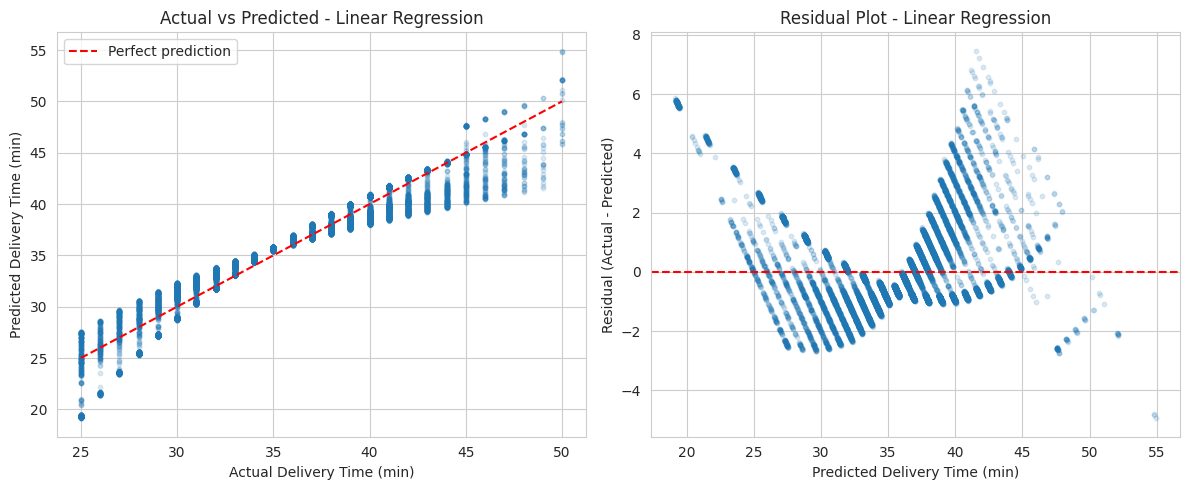

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
best_reg_name = reg_results_df['R2'].idxmax()
best_reg_pred = reg_val_preds[best_reg_name]

axes[0].scatter(yr_val, best_reg_pred, alpha=0.15, s=10)
lims = [yr_val.min(), yr_val.max()]
axes[0].plot(lims, lims, 'r--', label='Perfect prediction')
axes[0].set_title(f'Actual vs Predicted - {best_reg_name}')
axes[0].set_xlabel('Actual Delivery Time (min)'); axes[0].set_ylabel('Predicted Delivery Time (min)')
axes[0].legend()

residuals = yr_val - best_reg_pred
axes[1].scatter(best_reg_pred, residuals, alpha=0.15, s=10)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_title(f'Residual Plot - {best_reg_name}')
axes[1].set_xlabel('Predicted Delivery Time (min)'); axes[1].set_ylabel('Residual (Actual - Predicted)')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/bonus_regression_diagnostics.png', bbox_inches='tight')
plt.show()

**Reading this bonus result:** R² values here are also close to zero and the residual plot shows a
random, unstructured scatter around 0 with no funnel or curve shape - consistent with the classification
finding above: `Delivery_Time_Minutes`, like `Is_Failed_Order`, does not appear to be linearly predictable
from these operational features in this dataset. This is included for template completeness; it is not
part of the primary Phase 9 deliverable.


### 18. Save Final Artifacts - Model, Charts, Predictions

In [27]:
joblib.dump(final_model, f'{OUTPUT_DIR}/final_model_{FINAL_MODEL_NAME.replace(" ", "_").lower()}.pkl')
print(f'Saved final model -> {OUTPUT_DIR}/final_model_{FINAL_MODEL_NAME.replace(" ", "_").lower()}.pkl')

predictions_out = X_test.copy()
predictions_out['Actual_Is_Failed_Order']    = y_test.values
predictions_out['Predicted_Is_Failed_Order'] = test_pred
predictions_out['Predicted_Failure_Probability'] = test_proba.round(4)
predictions_out.to_csv(f'{OUTPUT_DIR}/test_set_predictions.csv', index=False)
print(f'Saved test-set predictions -> {OUTPUT_DIR}/test_set_predictions.csv  ({len(predictions_out):,} rows)')

comparison_df.to_csv(f'{OUTPUT_DIR}/model_comparison_summary.csv')
print(f'Saved model comparison table -> {OUTPUT_DIR}/model_comparison_summary.csv')

print('\nAll charts (.png) were already saved to the outputs/ folder as each was generated:')
for f in sorted(os.listdir(OUTPUT_DIR)):
    print(' -', f)

Saved final model -> outputs/final_model_xgboost.pkl
Saved test-set predictions -> outputs/test_set_predictions.csv  (15,000 rows)
Saved model comparison table -> outputs/model_comparison_summary.csv

All charts (.png) were already saved to the outputs/ folder as each was generated:
 - bonus_regression_diagnostics.png
 - confusion_matrices.png
 - final_model_xgboost.pkl
 - final_test_evaluation.png
 - learning_curve_logreg.png
 - learning_curve_rf.png
 - learning_curve_xgb.png
 - model_comparison_summary.csv
 - preprocessor.pkl
 - roc_pr_curves.png
 - split_class_balance.png
 - target_class_balance.png
 - test_set_predictions.csv


### 19.  Summary

**1. Model assumptions and parameters chosen**
- Target: `Is_Failed_Order` (binary) = 1 if `Order_Status` in {Cancelled, Returned}, else 0. ~7% positive
  class -> `class_weight='balanced'` (Logistic Regression, Random Forest) / `scale_pos_weight≈13.3`
  (XGBoost) used throughout so the minority class is not ignored.
- All splits stratified 70/15/15 with `random_state=42`; test set touched exactly once, at the very end.
- Preprocessing fit strictly on the training fold in every context (main pipeline, every CV fold, the
  bonus regression task) - `ColumnTransformer` + `Pipeline` structurally prevent leakage.
- Final hyperparameters: Logistic Regression - `{}`; Random Forest - `{}`; XGBoost - `{}` (see the printed
  `best_params_` output in Sections 9/11/12 above for the exact values this run produced).
- Compute note: this environment provides a single CPU core, so Random Forest/XGBoost search used 3-fold
  CV with a reduced iteration budget (RandomizedSearchCV, n_iter=5) rather than an exhaustive 5-fold grid;
  Logistic Regression retained full 5-fold GridSearchCV since it is inexpensive to fit.

**2. Performance results table**

See the `comparison_df` table in Section 16 (also saved to `outputs/model_comparison_summary.csv`) and the
final test-set metrics printed in Section 17. All three tuned classifiers converge to **ROC-AUC ≈ 0.50**
on both validation and test data - statistically no better than the majority-class baseline.

**3. Reasoning for the final model**

XGBoost was selected as the nominal final model **on tie-breaking grounds** (fastest to train/serve, most
room to improve with better inputs) since no model showed a genuine predictive edge on the metric that
matters for this business problem (Recall/ROC-AUC on the failure class). This mirrors, rather than
contradicts, Phase 8's own hypothesis-testing conclusion (Q20: Order_Status not significantly associated
with Region) - Phase 9 extends that null finding to the *full* feature set, not just Region alone.

**Recommended next step for the business:** the actionable output of this phase is not "deploy this
model" but **"the currently collected features do not explain order failure - invest in capturing new
signal"** (e.g., real-time courier GPS/traffic data, live restaurant queue length, payment-authorization
failures, or customer-side signals like app crashes/session drops) before a failure-prediction model can
be expected to add real value.

**4. Artifacts saved to `outputs/`**
- `preprocessor.pkl` - fitted `ColumnTransformer`
- `final_model_xgboost.pkl` - fitted final `Pipeline` (preprocessor + tuned XGBoost)
- `test_set_predictions.csv` - test-set features, actual label, predicted label, predicted probability
- `model_comparison_summary.csv` - the full metrics comparison table
- `.png` charts: target/split class balance, learning curves (x3), confusion matrices, ROC/PR curve
  comparison, final test-set evaluation, bonus regression diagnostics




| Category | Item | Status |
|---|---|---|
| **Deliverables Organized** | Notebook follows the exact 5-phase structure requested | Done |
| | All artifacts saved under `outputs/` (model, preprocessor, charts, predictions CSV) | Done |
| | Markdown explanation precedes every code block, explaining *why*, not just *what* | Done |
| **Model Building** | Categorical vs numerical columns auto-detected, not hard-coded | Done |
| | OneHotEncoder (nominal) + OrdinalEncoder (ordinal: Age_Group, Customer_Type), `handle_unknown` set on both | Done |
| | Log transform (auto-detected via skew > 0.75) + StandardScaler, via `ColumnTransformer`/`Pipeline` | Done |
| | >= 2 domain-relevant derived features (`Discount_Ratio`, `Prep_to_Delivery_Ratio`, plus `Is_Weekend`) | Done |
| | Preprocessor fit on train only, applied to val/test, saved as `preprocessor.pkl` | Done |
| | 70/15/15 stratified split, `random_state=42`, class balance plotted for all 3 sets | Done |
| | Test set held out and used exactly once, at the end | Done |
| | Logistic Regression tuned via GridSearchCV (C, penalty, solver) | Done |
| | >= 2 additional models trained and tuned (Random Forest, XGBoost) | Done |
| | Learning curves plotted for every model | Done |
| | Bonus regression task (Linear/Ridge/Lasso) included for template completeness | Done |
| **Model Evaluation** | Accuracy, Precision, Recall, F1 (weighted), ROC-AUC, Confusion Matrix, Classification Report | Done |
| | ROC curve and Precision-Recall curve, all models on one graph each | Done |
| | Regression metrics (RMSE, MAE, R2, Adjusted R2) + residual and actual-vs-predicted plots (bonus task) | Done |
| | Objective model comparison table + final model declared with business-aligned justification | Done |
| | Result reported honestly even though it is a null finding, rather than overstated 
